# Single-cell inference analysis

In-sample fit, cell ordering against the sorted populations, and network overlap with Hamey et al.'s
partial-correlation PKN, for the methods in `single_cell_inference/snapshot_tree_ilp.py`. Nothing is held out. The
PKN is not an inference input, so it is an independent reference, though not ground truth.

`stable_network_tree` is a benchmark that this notebook computes for each run: the network in which every gene
holds its value, with the tree of the heuristic's first tree step, a minimum Hamming forest of the neighbour graph.
Its repair step gives every cell the same state, so the tree shows only what the data's distances order. It appears
once per seed in `stable_tree_seeds`: the seed changes only how ties are broken, so the difference between them
shows how much a result can change by tie-breaking alone.

To compare runs, list their output folders in `runs`. Each folder holds one subfolder per method.

In [1]:
code_dir = "/home/abronner/TimeSeriesNetworkInference"
scratch_dir = "/scratch/gpfs/MONA/abronner/TimeSeriesNetworkInference"
data_dir = f"{scratch_dir}/data/single_cell_qpcr"
pkn_file = f"{scratch_dir}/data/hamey_pseudotime_inference/startingNetworkParCor.txt"
runs = {"all cells": f"{scratch_dir}/single_cell_inference/results/lmpp"}  # {label: the config's out folder}
tables_dir = f"{scratch_dir}/single_cell_inference/results/analysis_tables"  # a CSV per table and figure below
# Each breaks the ties of one stable_network_tree benchmark, which also place its roots. Seed 1 is left out since
# on the all-cells run it gives the same tree as snapshot_tree_heuristic, whose network is empty.
stable_tree_seeds = (0, 2)

# Differentiation depth for the rank correlation with pseudotime: the longest path from the HSCs in the hierarchy
# of Hamey et al. 2017, Fig. 1A, a DAG in which FSR-HSC is the data's ST-HSC. MEP is also one step from PreMegE.
population_rank = {"HSC1": 0, "HSC2": 0, "HSC3": 0, "HSC4": 0, "ST-HSC1": 1, "ST-HSC2": 1, "MPP": 2, "PreMegE": 2,
                   "LMPP": 3, "CMP": 3, "GMP": 4, "MEP": 4}

# The direct parent -> child links among these populations in the same figure, with HSC1-4 as the sorting strategies
# for its LT-HSC node and ST-HSC1-2 for its FSR-HSC node.
hierarchy_groups = {"HSC": ["HSC1", "HSC2", "HSC3", "HSC4"], "ST-HSC": ["ST-HSC1", "ST-HSC2"]}
hierarchy_edges = [("HSC", "ST-HSC"), ("ST-HSC", "MPP"), ("ST-HSC", "PreMegE"), ("MPP", "CMP"), ("MPP", "LMPP"),
                   ("PreMegE", "MEP"), ("CMP", "MEP"), ("CMP", "GMP"), ("LMPP", "GMP")]

In [2]:
import json
import os
import re
import sys

from IPython.display import display
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import scipy.cluster.hierarchy
import scipy.sparse
from scipy.sparse.csgraph import shortest_path
import scipy.stats

sys.path.insert(0, code_dir)
from attractor_learning.graphs import Network
from attractor_learning.logic import SymmetricThresholdFunction
from single_cell_inference import snapshot_tree_heuristic
from single_cell_inference.snapshot_tree_ilp import (METHODS, PSEUDO_ROOT, candidate_predecessors, load_detection_data,
                                                     lmpp_cells)

all_genes, all_cells, _, all_detected = load_detection_data(data_dir)
cell_rows = {name: row for row, name in enumerate(all_cells)}
gene_columns = {gene: column for column, gene in enumerate(all_genes)}


def signed_edges(network):
    """{(regulator, target): 1 | -1} of a network of threshold functions."""
    edges = {}
    for vertex in network.vertices:
        if isinstance(vertex.function, SymmetricThresholdFunction):
            for regulator, sign in zip(vertex.predecessors(), vertex.function.signs):
                edges[(regulator.name, vertex.name)] = 1 if sign else -1
    return edges


def solve_seconds(folder):
    """Gurobi's run time from the method's log; NaN for the heuristic and for runs without a log."""
    path = os.path.join(folder, "inference_log.txt")
    if not os.path.exists(path):
        return np.nan
    with open(path) as log_file:
        times = re.findall(r"^Explored .* in ([\d.]+) seconds", log_file.read(), flags=re.MULTILINE)
    return float(times[-1]) if times else np.nan


def tree_pseudotime(cells):
    """The depth of each of the {name: cell} cells in the result's tree, in their order, a child of the pseudo-root
    at 1. This is not the solution's "pseudotime": depth only bounds the ILP's tau from below."""
    depths = {}
    for name in cells:
        path, ancestor = [], name
        while ancestor is not None and ancestor not in depths:
            path.append(ancestor)
            ancestor = cells[ancestor]["predecessor"]
        depth = 0 if ancestor is None else depths[ancestor]
        for cell in reversed(path):
            depth += 1
            depths[cell] = depth
    return np.array([depths[name] for name in cells])


def make_result(run, method, solution, edges, seconds):
    names, genes = list(solution["cells"]), solution["genes"]
    cells = [solution["cells"][name] for name in names]
    return {"run": run, "method": method, "label": f"{run}\n{method}", "solution": solution, "genes": genes,
            "detected": all_detected[np.ix_([cell_rows[name] for name in names],
                                            [gene_columns[gene] for gene in genes])],
            "states": np.array([cell["state"] for cell in cells]),
            "unstable": np.array([[gene in cell["unstable"] for gene in genes] for cell in cells]),
            "populations": np.array([cell["cell_type"] for cell in cells]),
            "pseudotime": tree_pseudotime(solution["cells"]),
            "roots": sum(cell["predecessor"] is None for cell in cells),
            "edges": edges, "seconds": seconds}


def load_result(run, method, folder):
    with open(os.path.join(folder, "cells.json")) as cells_file:
        solution = json.load(cells_file)
    return make_result(run, method, solution, signed_edges(Network.load(os.path.join(folder, "network.json"))),
                       solve_seconds(folder))


def stable_network_result(reference, seed):
    """The stable_network_tree benchmark on the cells, genes and options of another result of the run."""
    solution, detected = reference["solution"], reference["detected"]
    names, options = list(solution["cells"]), solution["options"]
    root_penalty = 6.0 / len(reference["genes"]) if options["root_penalty"] is None else options["root_penalty"]
    predecessors = candidate_predecessors(detected, options["k"])
    parent = snapshot_tree_heuristic.build_tree(detected, None, predecessors, root_penalty, seed=seed)
    states, pseudotime = snapshot_tree_heuristic.repair_states(detected, None, parent)
    value, _ = snapshot_tree_heuristic.objective(detected, None, states, parent, options["edge_penalty"],
                                                 options["stability_penalty"], root_penalty)
    cells = {name: {"predecessor": None if parent[c] == PSEUDO_ROOT else names[parent[c] - 1],
                    "pseudotime": pseudotime[c], "state": states[c], "unstable": [],
                    "cell_type": reference["populations"][c - 1]} for c, name in enumerate(names, start=1)}
    benchmark = {"genes": reference["genes"], "cells": cells, "objective": value, "options": options}
    return make_result(reference["run"], f"stable_network_tree_seed{seed}", benchmark, {}, np.nan)


results = [load_result(run, method, os.path.join(folder, method)) for run, folder in runs.items()
           for method in METHODS if os.path.exists(os.path.join(folder, method, "cells.json"))]
references = {result["run"]: result for result in results}.values()
results += [stable_network_result(reference, seed) for reference in references for seed in stable_tree_seeds]
print(len(results), "results")
os.makedirs(tables_dir, exist_ok=True)

5 results


## Fit

Objectives are on the cells, so they compare across methods with the same penalties. Solver objective, bound and
gap are the solver's own: for `medoid_tree_ilp` they are on the groups, before the tree is rebuilt on the cells.

In [3]:
def fit_row(result):
    solution, options = result["solution"], result["solution"]["options"]
    has_bound = "bound" in solution
    solver_objective = solution["objective"] if has_bound else np.nan
    bound = solution["bound"] if has_bound else np.nan
    return {"run": result["run"], "method": result["method"], "cells": len(result["states"]),
            "edge penalty": options["edge_penalty"], "stability penalty": options["stability_penalty"],
            "objective": solution.get("cell_objective", solution["objective"]),
            "solver objective": solver_objective, "bound": bound,
            "gap %": 100 * (bound - solver_objective) / abs(solver_objective),
            "edges": len(result["edges"]), "roots": result["roots"],
            "flipped bits %": 100 * (result["states"] != result["detected"]).mean(),
            "unstable bits %": 100 * result["unstable"].mean(),
            "max pseudotime": result["pseudotime"].max(), "solve seconds": result["seconds"]}


fit_table = pd.DataFrame([fit_row(result) for result in results]).set_index(["run", "method"])
fit_table.to_csv(os.path.join(tables_dir, "fit.csv"))
display(fit_table.round(4))

cells  edge penalty  stability penalty  \
run       method                                                              
all cells snapshot_tree_ilp           2167           1.0               0.08   
          medoid_tree_ilp             2167           1.0               0.08   
          snapshot_tree_heuristic     2167           1.0               0.08   
          stable_network_tree_seed0   2167           1.0               0.08   
          stable_network_tree_seed2   2167           1.0               0.08   

                                     objective  solver objective   bound  \
run       method                                                           
all cells snapshot_tree_ilp             0.8443            0.8443  1.0000   
          medoid_tree_ilp               0.7783            0.8955  0.9199   
          snapshot_tree_heuristic       0.7483               NaN     NaN   
          stable_network_tree_seed0     0.6554               NaN     NaN   
          stable_network_tree_seed2     0.7230               NaN     NaN   

                                       gap %  edges  roots  flipped bits %  \
run       method                                                             
all cells snapshot_tree_ilp          18.4362     28      1         13.3013   
          medoid_tree_ilp             2.7190     47      1         21.4429   
          snapshot_tree_heuristic        NaN     36      1         23.6920   
          stable_network_tree_seed0      NaN      0      1         34.4453   
          stable_network_tree_seed2      NaN      0      1         27.6859   

                                     unstable bits %  max pseudotime  \
run       method                                                       
all cells snapshot_tree_ilp                  25.1983              16   
          medoid_tree_ilp                     4.0005              50   
          snapshot_tree_heuristic            14.5450              34   
          stable_network_tree_seed0           0.0000              84   
          stable_network_tree_seed2           0.0000              56   

                                     solve seconds  
run       method                                    
all cells snapshot_tree_ilp               52027.09  
          medoid_tree_ilp                 52000.52  
          snapshot_tree_heuristic              NaN  
          stable_network_tree_seed0            NaN  
          stable_network_tree_seed2            NaN

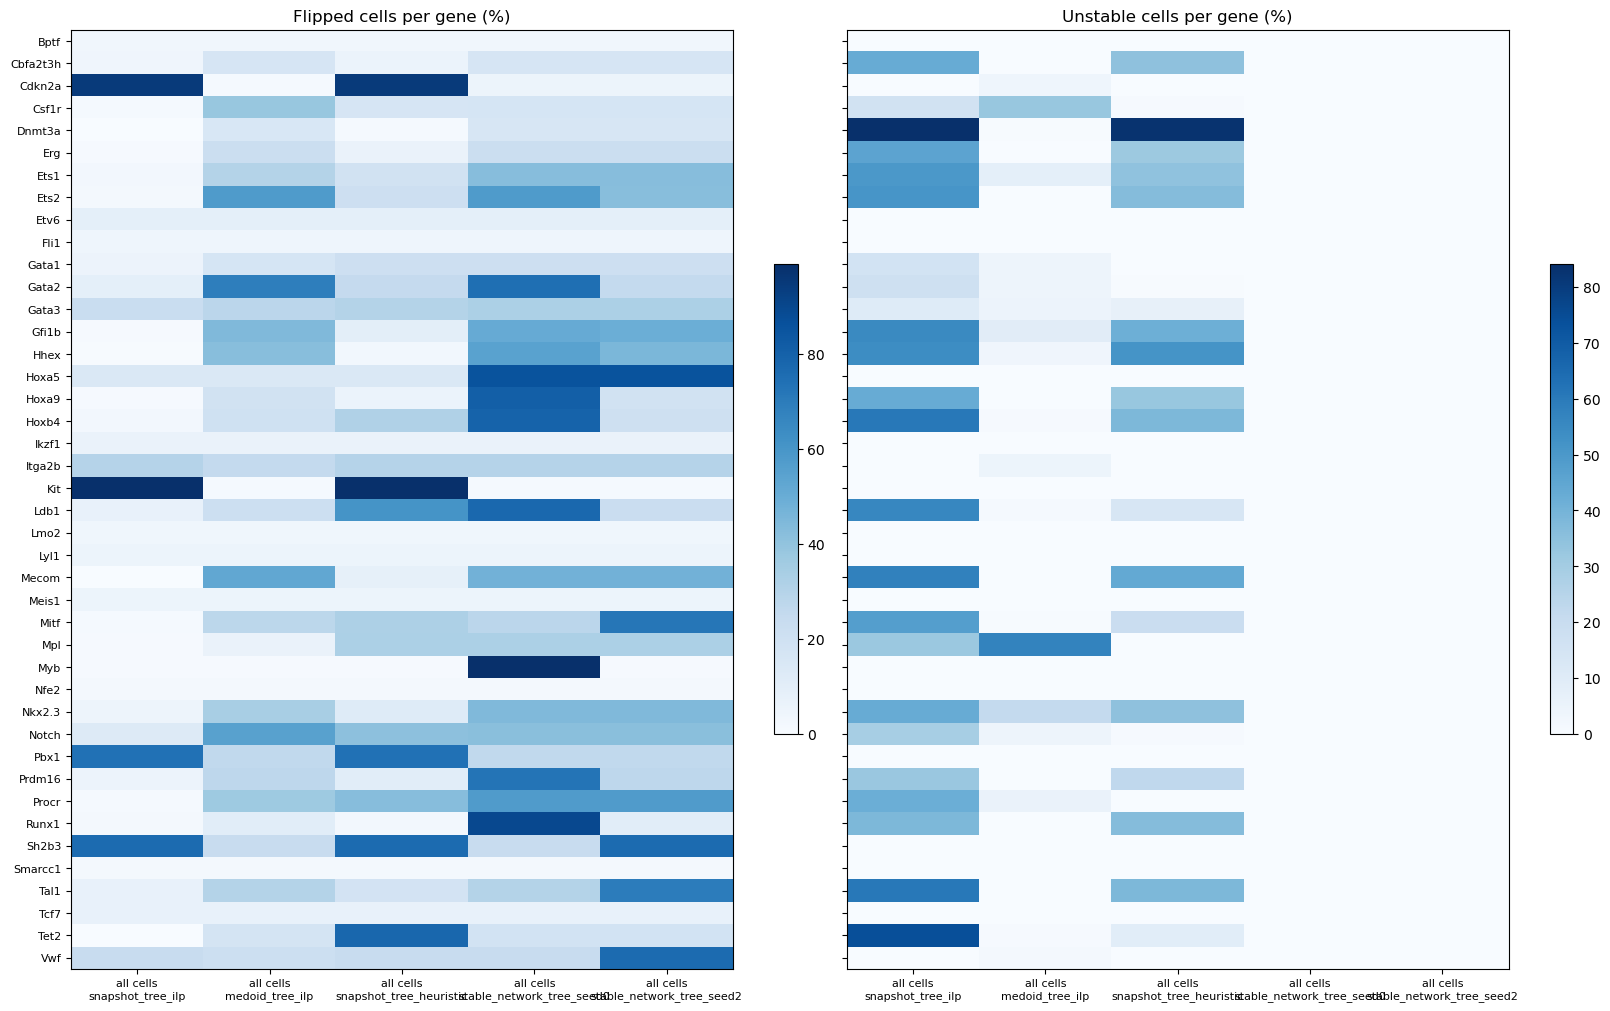

In [4]:
def gene_table(values):
    """Percentages per gene (rows) and result (columns), from a cells x genes array per result."""
    return pd.DataFrame({result["label"]: pd.Series(100 * values(result).mean(axis=0), index=result["genes"])
                         for result in results})


tables = {"Flipped cells per gene (%)": gene_table(lambda result: result["states"] != result["detected"]),
          "Unstable cells per gene (%)": gene_table(lambda result: result["unstable"])}
gene_rates = pd.concat({title: table.stack() for title, table in tables.items()},
                       names=["metric", "gene", "result"]).rename("percent").reset_index()
gene_rates["result"] = gene_rates["result"].str.replace("\n", ", ")
gene_rates.to_csv(os.path.join(tables_dir, "gene_rates.csv"), index=False)

figure, axes = plt.subplots(1, 2, figsize=(4 + 2.4 * len(results), 10), constrained_layout=True, sharey=True)
for axis, (title, table) in zip(axes, tables.items()):
    image = axis.imshow(table.values, aspect="auto", cmap="Blues", vmin=0)
    axis.set_title(title)
    axis.set_xticks(range(table.shape[1]), table.columns, fontsize=8)
    axis.set_yticks(range(table.shape[0]), table.index, fontsize=8)
    figure.colorbar(image, ax=axis, shrink=0.5)
plt.show()

## Cell ordering

Pseudotime is a cell's depth in the result's tree, from the predecessors, here and in the sections below.

Pseudotime per sorted population, by differentiation depth: the longest path from the HSCs in Hamey et al. 2017,
Fig. 1A. Spearman's rho is between pseudotime and `population_rank`, over all cells of the result. Rho tests depth
only, not the separation of branches.

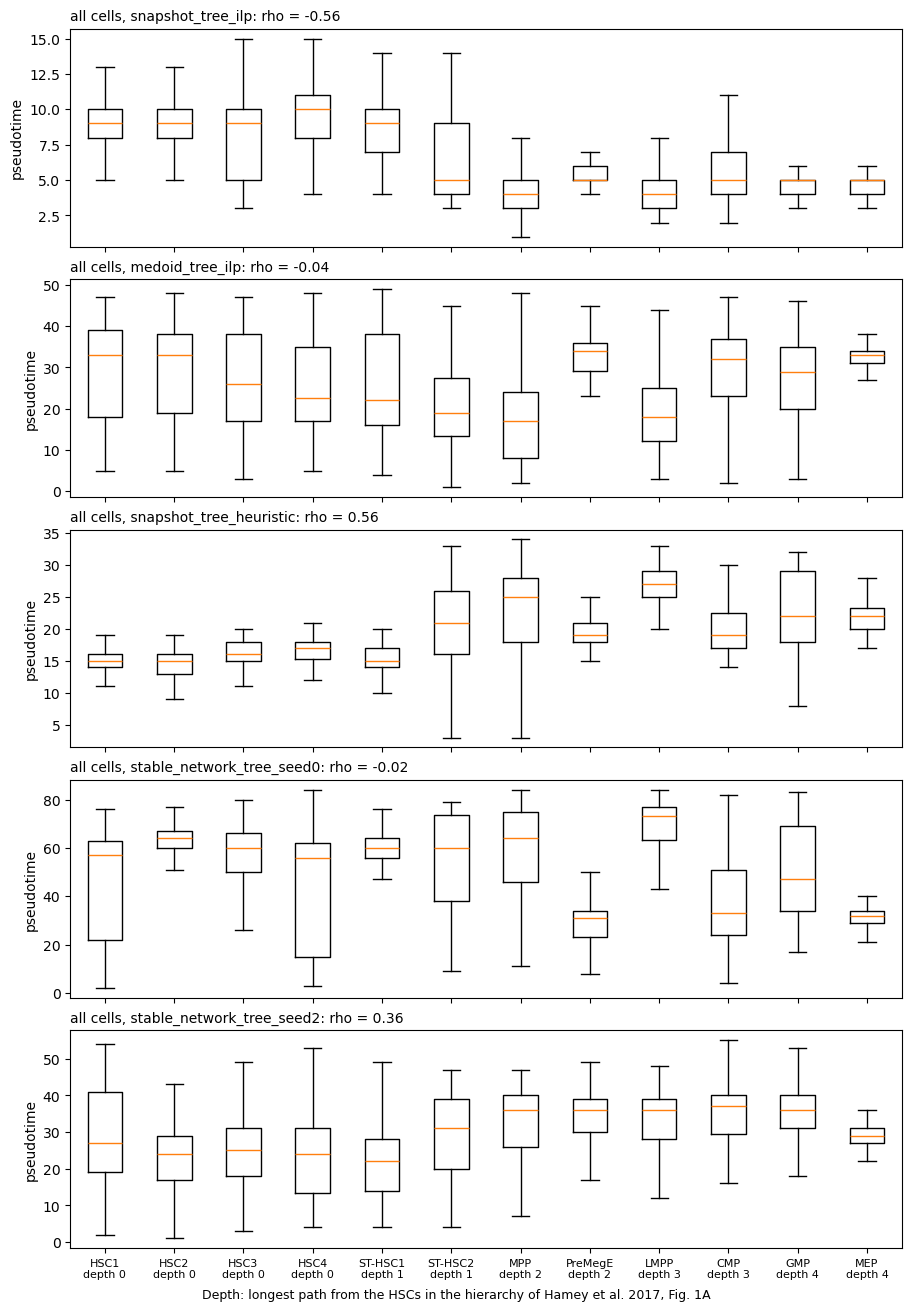

Spearman rho
run       method                                 
all cells snapshot_tree_ilp                -0.560
          medoid_tree_ilp                  -0.039
          snapshot_tree_heuristic           0.558
          stable_network_tree_seed0        -0.022
          stable_network_tree_seed2         0.359

In [5]:
populations = sorted(population_rank, key=population_rank.get)
figure, axes = plt.subplots(len(results), 1, figsize=(9, 2.6 * len(results)), constrained_layout=True, squeeze=False,
                            sharex=True)
ordering, by_population = [], []
for axis, result in zip(axes[:, 0], results):
    ranks = [population_rank[population] for population in result["populations"]]
    rho = scipy.stats.spearmanr(result["pseudotime"], ranks)[0]
    ordering.append({"run": result["run"], "method": result["method"], "Spearman rho": rho})
    present = [population for population in populations if (result["populations"] == population).any()]
    for population in present:
        times = result["pseudotime"][result["populations"] == population]
        q1, median, q3 = np.percentile(times, [25, 50, 75])
        by_population.append({"run": result["run"], "method": result["method"], "population": population,
                              "cells": len(times), "q1": q1, "median": median, "q3": q3})
    axis.boxplot([result["pseudotime"][result["populations"] == population] for population in present],
                 positions=[populations.index(population) for population in present], showfliers=False)
    axis.set_xticks(range(len(populations)),
                    [f"{population}\ndepth {population_rank[population]}" for population in populations],
                    fontsize=8)
    axis.set_ylabel("pseudotime")
    axis.set_title(f"{result['run']}, {result['method']}: rho = {rho:.2f}", fontsize=10, loc="left")
figure.supxlabel("Depth: longest path from the HSCs in the hierarchy of Hamey et al. 2017, Fig. 1A", fontsize=9)
plt.show()
pd.DataFrame(by_population).to_csv(os.path.join(tables_dir, "pseudotime_by_population.csv"), index=False)
ordering_table = pd.DataFrame(ordering).set_index(["run", "method"])
ordering_table.to_csv(os.path.join(tables_dir, "ordering.csv"))
display(ordering_table.round(3))

### Hierarchy links

Pairs of a cell in a population and a cell in a direct child of that population in Hamey et al. 2017, Fig. 1A. Every
such pair of cells is counted, whether or not one descends from the other in the result's tree. Equal pseudotimes
count as not increasing. The difference is the child cell's pseudotime minus the parent cell's. "All links" pools the
pairs of every link, so it weights links by their number of cell pairs.

The dashed lines are two benchmarks: 0.5, and the fraction of pairs increasing if pseudotime were depth in the
hierarchy (`population_rank`) and cells were shuffled among the populations, keeping the population sizes. The second
is below 0.5 because cells at the same depth tie, and it is the same for every link.

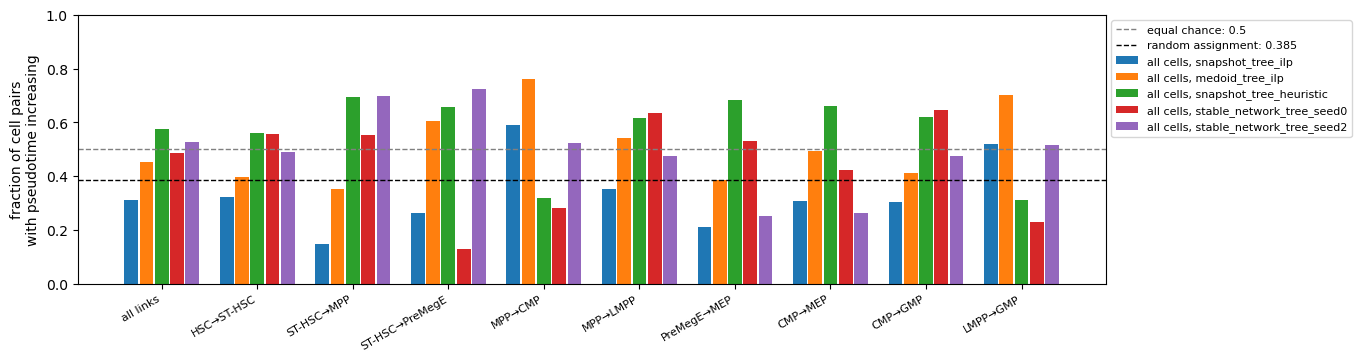

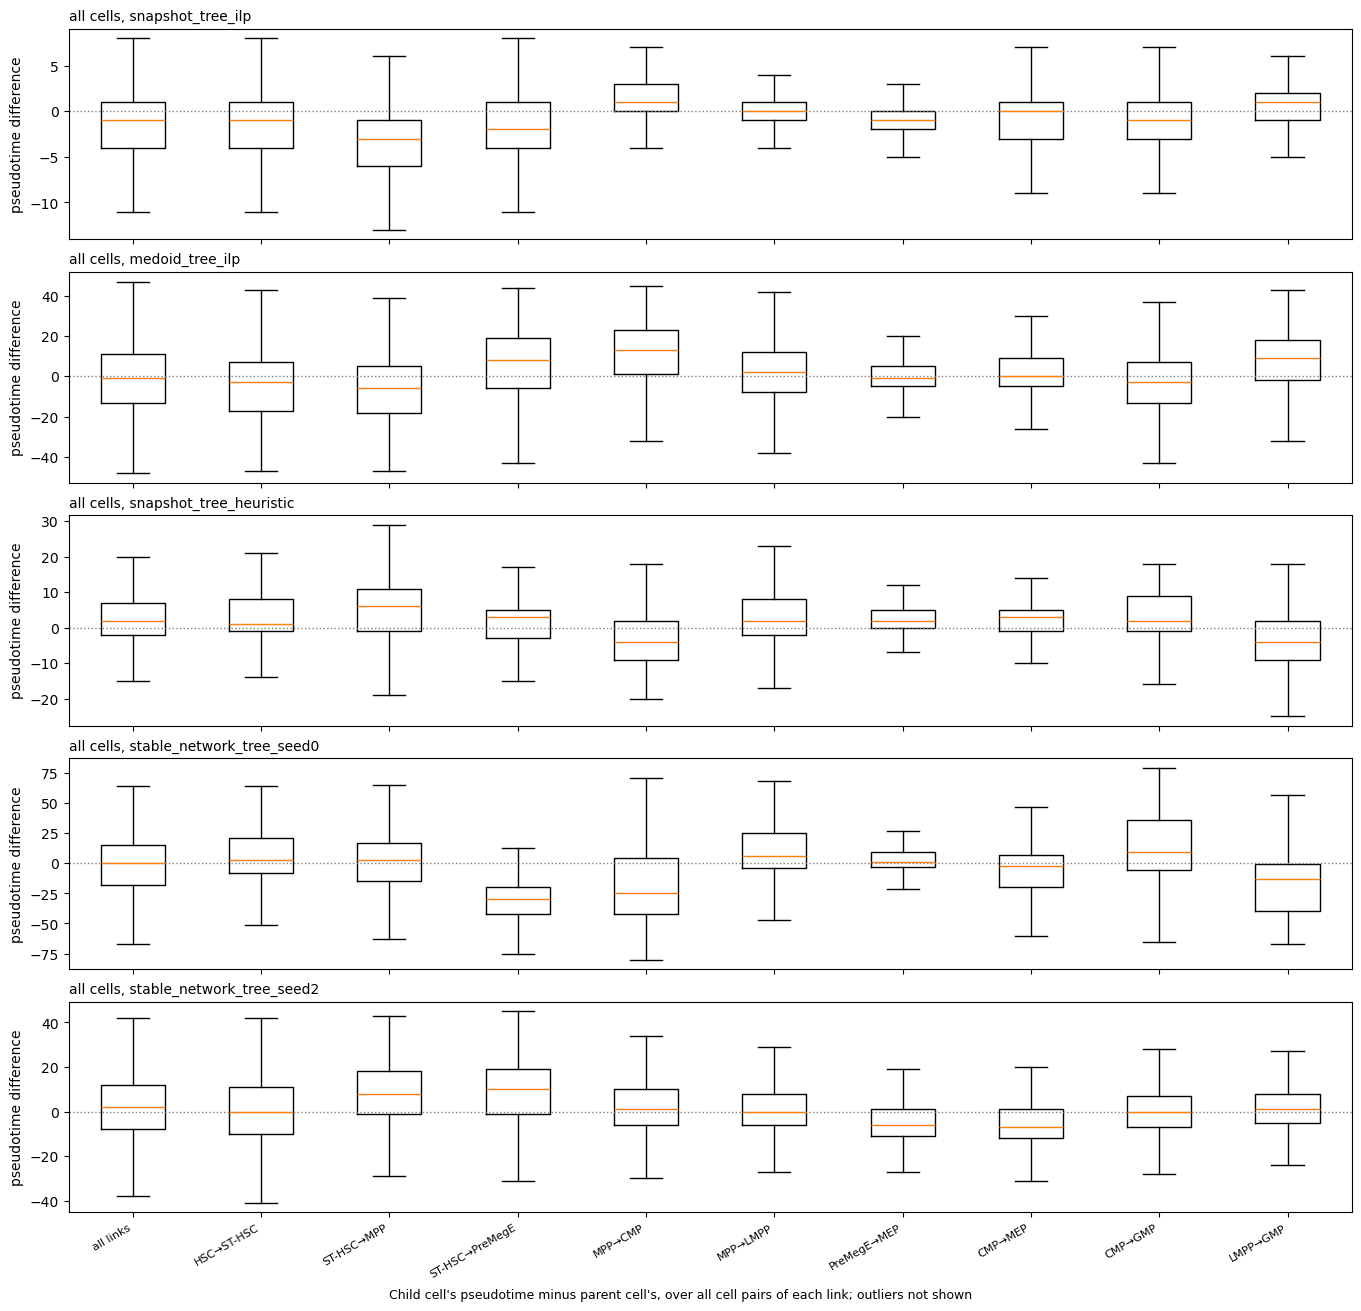

link                                 all links  HSC→ST-HSC  ST-HSC→MPP  \
run       method                                                         
all cells medoid_tree_ilp                0.455       0.396       0.351   
          snapshot_tree_heuristic        0.577       0.561       0.695   
          snapshot_tree_ilp              0.313       0.324       0.147   
          stable_network_tree_seed0      0.486       0.557       0.553   
          stable_network_tree_seed2      0.529       0.490       0.699   

link                                 ST-HSC→PreMegE  MPP→CMP  MPP→LMPP  \
run       method                                                         
all cells medoid_tree_ilp                     0.604    0.761     0.543   
          snapshot_tree_heuristic             0.658    0.318     0.615   
          snapshot_tree_ilp                   0.263    0.589     0.351   
          stable_network_tree_seed0           0.130    0.281     0.637   
          stable_network_tree_seed2           0.723    0.522     0.475   

link                                 PreMegE→MEP  CMP→MEP  CMP→GMP  LMPP→GMP  
run       method                                                              
all cells medoid_tree_ilp                  0.385    0.495    0.411     0.703  
          snapshot_tree_heuristic          0.684    0.662    0.621     0.310  
          snapshot_tree_ilp                0.213    0.308    0.303     0.518  
          stable_network_tree_seed0        0.533    0.424    0.646     0.229  
          stable_network_tree_seed2        0.253    0.264    0.474     0.515

In [6]:
def link_differences(result):
    """{"parent→child": the child cell's pseudotime minus the parent cell's, over all such pairs of cells}, without
    links to an absent population, after "all links", which pools the others."""
    def times(population):
        return result["pseudotime"][np.isin(result["populations"], hierarchy_groups.get(population, [population]))]

    differences = {f"{parent}→{child}": np.subtract.outer(times(child), times(parent)).ravel()
                   for parent, child in hierarchy_edges}
    differences = {link: values for link, values in differences.items() if values.size}
    return {"all links": np.concatenate(list(differences.values())), **differences}


def link_row(result, link, values):
    q1, median, q3 = np.percentile(values, [25, 50, 75])
    return {"run": result["run"], "method": result["method"], "link": link, "cell pairs": len(values),
            "fraction increasing": (values > 0).mean(), "fraction tied": (values == 0).mean(),
            "q1": q1, "median": median, "q3": q3}


def random_assignment_fraction(result):
    """The fraction of pairs of cells whose pseudotime increases, in expectation, if pseudotime is depth in the
    hierarchy and cells are shuffled among the populations: half of the pairs at different depths."""
    counts = np.unique([population_rank[population] for population in result["populations"]], return_counts=True)[1]
    cells = counts.sum()
    return (1 - (counts * (counts - 1)).sum() / (cells * (cells - 1))) / 2


links = ["all links"] + [f"{parent}→{child}" for parent, child in hierarchy_edges]
differences = [link_differences(result) for result in results]
link_table = pd.DataFrame([link_row(result, link, values) for result, by_link in zip(results, differences)
                           for link, values in by_link.items()]).set_index(["run", "method", "link"])
link_table.to_csv(os.path.join(tables_dir, "hierarchy_links.csv"))

figure, axis = plt.subplots(figsize=(2.5 + 1.1 * len(links), 3.5), constrained_layout=True)
width = 0.8 / len(results)
for index, (result, by_link) in enumerate(zip(results, differences)):
    positions = [links.index(link) + (index - (len(results) - 1) / 2) * width for link in by_link]
    axis.bar(positions, [(values > 0).mean() for values in by_link.values()], width * 0.9,
             label=result["label"].replace("\n", ", "))
axis.axhline(0.5, color="gray", linewidth=1, linestyle="--", label="equal chance: 0.5")
for fraction in sorted({random_assignment_fraction(result) for result in results}):
    axis.axhline(fraction, color="black", linewidth=1, linestyle="--", label=f"random assignment: {fraction:.3f}")
axis.set_xticks(range(len(links)), links, fontsize=8, rotation=30, ha="right")
axis.set_ylim(0, 1)
axis.set_ylabel("fraction of cell pairs\nwith pseudotime increasing")
axis.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

figure, axes = plt.subplots(len(results), 1, figsize=(2.5 + 1.1 * len(links), 2.6 * len(results)),
                            constrained_layout=True, squeeze=False, sharex=True)
for axis, result, by_link in zip(axes[:, 0], results, differences):
    axis.boxplot(list(by_link.values()), positions=[links.index(link) for link in by_link], showfliers=False)
    axis.axhline(0, color="gray", linewidth=1, linestyle=":")
    axis.set_xticks(range(len(links)), links, fontsize=8, rotation=30, ha="right")
    axis.set_ylabel("pseudotime difference")
    axis.set_title(f"{result['run']}, {result['method']}", fontsize=10, loc="left")
figure.supxlabel("Child cell's pseudotime minus parent cell's, over all cell pairs of each link; outliers not shown",
                 fontsize=9)
plt.show()
display(link_table["fraction increasing"].unstack("link").reindex(columns=links).round(3))

### Tree topology

The hierarchy has 8 nodes and an inferred tree has one vertex per cell, so shape statistics compare only relative
values, and the rest is compared on the hierarchy's nodes, with a cell at the node of its sorted population. The table
gives the shape, the hierarchy's on its nodes; depth counts edges from a root. Widths are the share of vertices per
depth, in five equal bins of depth over maximum depth; the hierarchy's five depths are weighted by their cells.

Tree edges are classed by the nodes of the parent and child cell: the same node, a link of Fig. 1A in its direction or
against it, or any other pair of nodes. "Random, cell pairs" is the expectation for a parent and child drawn at random.

Distances are the mean undirected path length between the cells of two nodes, and for the hierarchy the shortest
undirected path between the nodes. Rho is Spearman's, over the pairs of different nodes. Paths between trees of a forest
pass through the pseudo-root, and otherwise distances do not depend on where the roots are. The heatmaps' axes
follow an average-linkage clustering of the hierarchy's distances, with the same order in every panel.

vertices  roots  depth  \
run               method                                              
Hamey et al. 2017 Fig. 1A                         8.0    1.0    4.0   
all cells         snapshot_tree_ilp            2167.0    1.0   15.0   
                  medoid_tree_ilp              2167.0    1.0   49.0   
                  snapshot_tree_heuristic      2167.0    1.0   33.0   
                  stable_network_tree_seed0    2167.0    1.0   83.0   
                  stable_network_tree_seed2    2167.0    1.0   55.0   

                                             max width %  leaves %  \
run               method                                             
Hamey et al. 2017 Fig. 1A                         25.000    25.000   
all cells         snapshot_tree_ilp               18.320    65.251   
                  medoid_tree_ilp                  4.384    56.114   
                  snapshot_tree_heuristic         11.444    63.636   
                  stable_network_tree_seed0        3.276    47.993   
                  stable_network_tree_seed2        4.153    48.177   

                                             branching %  \
run               method                                   
Hamey et al. 2017 Fig. 1A                         37.500   
all cells         snapshot_tree_ilp               16.844   
                  medoid_tree_ilp                 22.658   
                  snapshot_tree_heuristic         19.935   
                  stable_network_tree_seed0       26.257   
                  stable_network_tree_seed2       25.611   

                                             children per internal vertex  \
run               method                                                    
Hamey et al. 2017 Fig. 1A                                           1.500   
all cells         snapshot_tree_ilp                                 2.876   
                  medoid_tree_ilp                                   2.278   
                  snapshot_tree_heuristic                           2.749   
                  stable_network_tree_seed0                         1.922   
                  stable_network_tree_seed2                         1.929   

                                             distance rho  
run               method                                   
Hamey et al. 2017 Fig. 1A                             NaN  
all cells         snapshot_tree_ilp                 0.322  
                  medoid_tree_ilp                   0.372  
                  snapshot_tree_heuristic           0.359  
                  stable_network_tree_seed0         0.361  
                  stable_network_tree_seed2         0.330

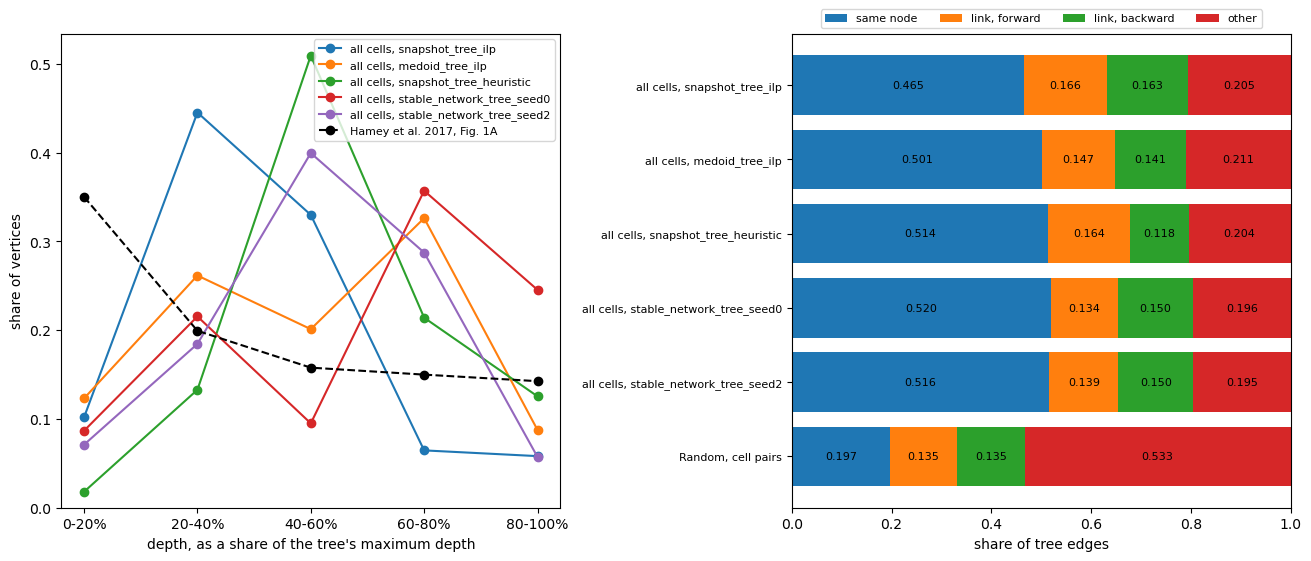

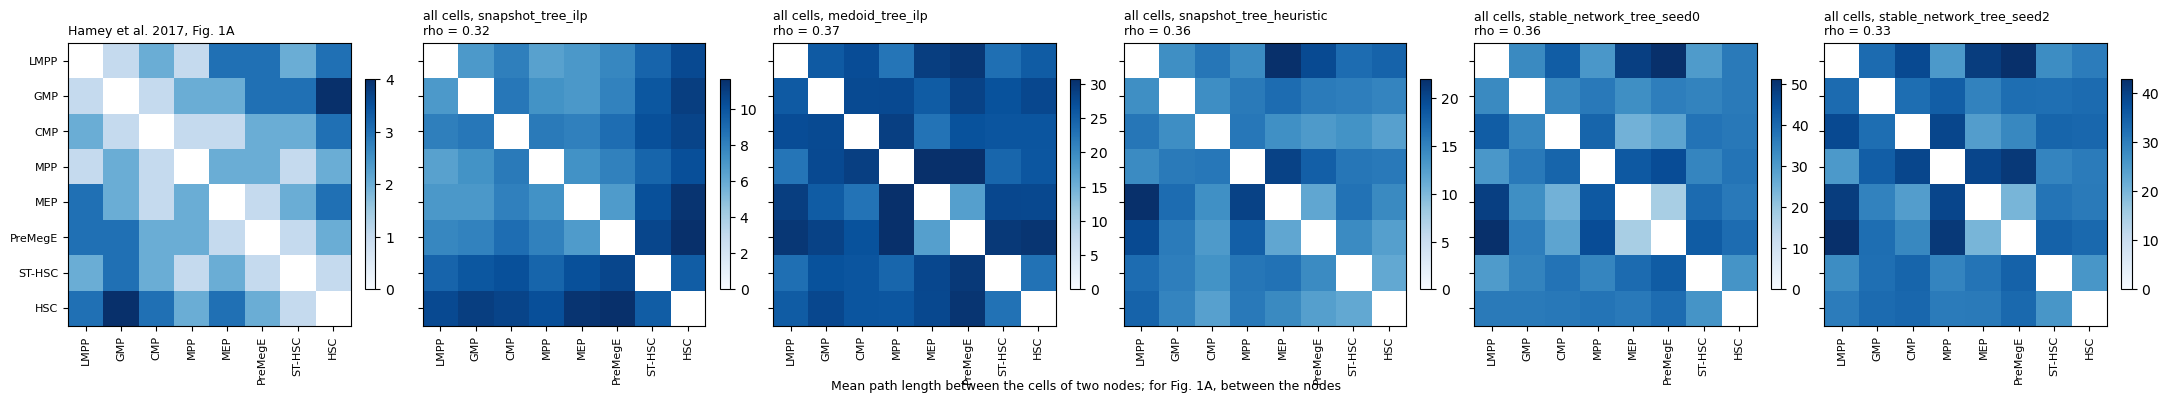

In [7]:
population_node = {population: node for node, group in hierarchy_groups.items() for population in group}
nodes = sorted({population_node.get(population, population) for population in population_rank},
               key=lambda node: population_rank[hierarchy_groups.get(node, [node])[0]])
node_rows = {node: row for row, node in enumerate(nodes)}
node_depths = np.array([population_rank[hierarchy_groups.get(node, [node])[0]] for node in nodes])
node_edges = [(node_rows[parent], node_rows[child]) for parent, child in hierarchy_edges]
node_pairs = np.triu_indices(len(nodes), 1)
real_key = ("Hamey et al. 2017", "Fig. 1A")


def undirected_distances(n_vertices, edges):
    """n_vertices x n_vertices shortest path lengths, ignoring direction, over (parent, child) edges."""
    parents, children = zip(*edges)
    graph = scipy.sparse.coo_matrix((np.ones(len(edges)), (parents, children)), shape=(n_vertices, n_vertices))
    return shortest_path(graph, directed=False, unweighted=True)


def tree_edges(result):
    """The tree's (parent, child) pairs of cell rows, with -1 for the pseudo-root."""
    cells = result["solution"]["cells"]
    rows = {name: row for row, name in enumerate(cells)}
    return [(rows.get(cell["predecessor"], -1), rows[name]) for name, cell in cells.items()]


def shape_row(depths, edges):
    """Shape of a tree or of the hierarchy, from its vertices' depths and its (parent, child) edges."""
    children = np.bincount([parent for parent, _ in edges], minlength=len(depths))
    widths = np.bincount(depths)
    return {"vertices": len(depths), "roots": len(depths) - len({child for _, child in edges}), "depth": depths.max(),
            "max width %": 100 * widths.max() / len(depths), "leaves %": 100 * (children == 0).mean(),
            "branching %": 100 * (children >= 2).mean(), "children per internal vertex": children[children > 0].mean()}


def edge_classes(counts):
    """Fraction per class of a nodes x nodes array of (parent, child) counts."""
    forward = sum(counts[edge] for edge in node_edges)
    backward = sum(counts[edge[::-1]] for edge in node_edges)
    same = np.trace(counts)
    classes = {"same node": same, "link, forward": forward, "link, backward": backward,
               "other": counts.sum() - same - forward - backward}
    return {name: value / counts.sum() for name, value in classes.items()}


def node_distances(result, cell_nodes):
    """Nodes x nodes mean path length between the cells of two nodes, NaN on the diagonal and for absent nodes."""
    distances = undirected_distances(len(cell_nodes) + 1, [(a + 1, c + 1) for a, c in tree_edges(result)])[1:, 1:]
    members = np.eye(len(nodes))[cell_nodes]
    sizes = members.sum(axis=0)
    with np.errstate(invalid="ignore", divide="ignore"):
        means = members.T @ distances @ members / np.outer(sizes, sizes)
    np.fill_diagonal(means, np.nan)
    return means


real_distances = undirected_distances(len(nodes), node_edges)
np.fill_diagonal(real_distances, np.nan)
shapes = {real_key: shape_row(node_depths, node_edges)}
widths, classes, distance_matrices = {}, {}, {real_key: real_distances}
for result in results:
    key = (result["run"], result["method"])
    depths, edges = result["pseudotime"] - 1, tree_edges(result)
    cell_edges = np.array([edge for edge in edges if edge[0] >= 0]).reshape(-1, 2)
    cell_nodes = np.array([node_rows[population_node.get(population, population)]
                           for population in result["populations"]])
    distance_matrices[key] = node_distances(result, cell_nodes)
    measured = ~np.isnan(distance_matrices[key][node_pairs])
    rho = scipy.stats.spearmanr(distance_matrices[key][node_pairs][measured], real_distances[node_pairs][measured])[0]
    shapes[key] = dict(shape_row(depths, cell_edges), **{"distance rho": rho})
    widths[key] = np.histogram(depths / depths.max(), bins=5, range=(0, 1))[0] / len(depths)
    counts = np.zeros((len(nodes), len(nodes)))
    np.add.at(counts, (cell_nodes[cell_edges[:, 0]], cell_nodes[cell_edges[:, 1]]), 1)
    classes[key] = edge_classes(counts)
sizes = np.bincount(cell_nodes, minlength=len(nodes))
widths[real_key] = np.bincount(node_depths, weights=sizes) / sizes.sum()
classes[("Random", "cell pairs")] = edge_classes(np.outer(sizes, sizes) - np.diag(sizes))

shape_table = pd.DataFrame(shapes).T.rename_axis(["run", "method"])
shape_table.to_csv(os.path.join(tables_dir, "tree_shape.csv"))
width_table = pd.DataFrame(widths, index=[f"{i * 20}-{(i + 1) * 20}%" for i in range(5)]).T
width_table.rename_axis(["run", "method"]).to_csv(os.path.join(tables_dir, "tree_widths.csv"))
class_table = pd.DataFrame(classes).T.rename_axis(["run", "method"])
class_table.to_csv(os.path.join(tables_dir, "tree_edge_classes.csv"))
pd.concat({key: pd.DataFrame(matrix, index=nodes, columns=nodes).stack() for key, matrix in distance_matrices.items()},
          names=["run", "method", "node", "other node"]).rename("distance").to_csv(
    os.path.join(tables_dir, "tree_distances.csv"))
display(shape_table.round(3))

figure, (width_axis, class_axis) = plt.subplots(1, 2, figsize=(13, 2.5 + 0.5 * len(class_table)),
                                                constrained_layout=True)
for key, row in width_table.iterrows():
    width_axis.plot(width_table.columns, row.values, marker="o", color="black" if key == real_key else None,
                    linestyle="--" if key == real_key else "-", label=", ".join(key))
width_axis.set_xlabel("depth, as a share of the tree's maximum depth")
width_axis.set_ylabel("share of vertices")
width_axis.set_ylim(bottom=0)
width_axis.legend(fontsize=8)
labels = [", ".join(key) for key in class_table.index]
left = np.zeros(len(class_table))
for name in class_table.columns:
    bars = class_axis.barh(labels, class_table[name].values, left=left, label=name)
    class_axis.bar_label(bars, fmt="%.3f", label_type="center", fontsize=8)
    left = left + class_table[name].values
class_axis.invert_yaxis()
class_axis.set_xlim(0, 1)
class_axis.set_xlabel("share of tree edges")
class_axis.tick_params(axis="y", labelsize=8)
class_axis.legend(fontsize=8, ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1))
plt.show()

node_order = scipy.cluster.hierarchy.leaves_list(
    scipy.cluster.hierarchy.linkage(real_distances[node_pairs], method="average", optimal_ordering=True))
ordered_nodes = [nodes[row] for row in node_order]
figure, axes = plt.subplots(1, len(distance_matrices), figsize=(3.6 * len(distance_matrices), 3.8),
                            constrained_layout=True, squeeze=False, sharey=True)
for axis, (key, matrix) in zip(axes[0], distance_matrices.items()):
    image = axis.imshow(matrix[np.ix_(node_order, node_order)], cmap="Blues", vmin=0)
    axis.set_xticks(range(len(nodes)), ordered_nodes, fontsize=8, rotation=90)
    axis.set_yticks(range(len(nodes)), ordered_nodes, fontsize=8)
    title = ", ".join(key)
    if key != real_key:
        title += f"\nrho = {shapes[key]['distance rho']:.2f}"
    axis.set_title(title, fontsize=9, loc="left")
    figure.colorbar(image, ax=axis, shrink=0.7)
figure.supxlabel("Mean path length between the cells of two nodes; for Fig. 1A, between the nodes", fontsize=9)
plt.show()

### Hamey et al.'s LMPP order

Pseudotime against the rank of each cell in Hamey et al.'s Wanderlust order of the HSC -> LMPP branch, the only order
of theirs available, which gives ranks and not pseudotime values. It covers 531 cells. Rho is Spearman's, over those
cells. Its sign depends on where the tree's roots are, which is arbitrary for a stable network.

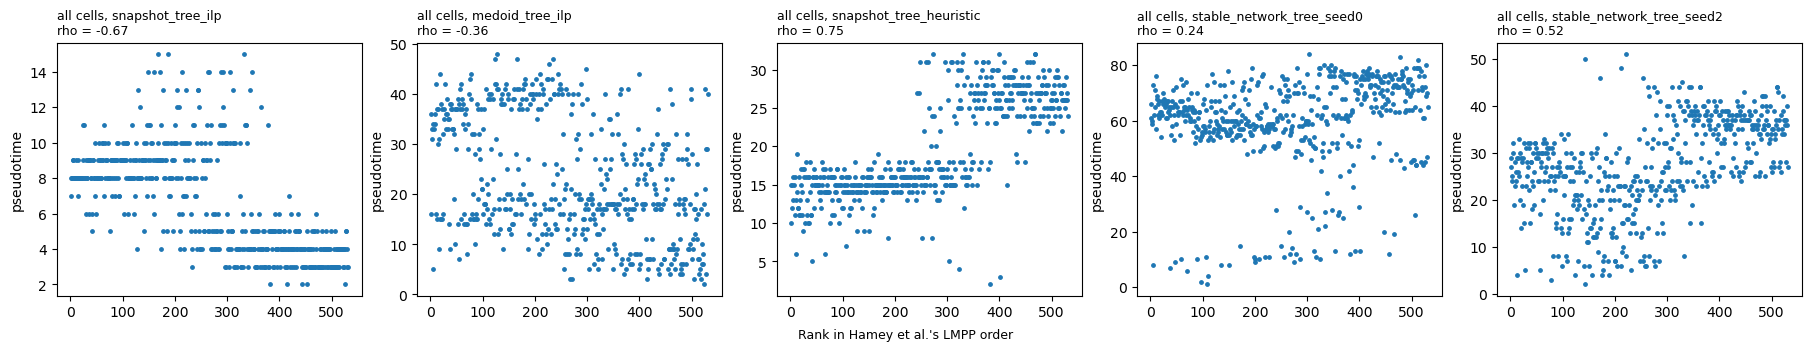

cells  Spearman rho
run       method                                        
all cells snapshot_tree_ilp            531        -0.671
          medoid_tree_ilp              531        -0.363
          snapshot_tree_heuristic      531         0.748
          stable_network_tree_seed0    531         0.243
          stable_network_tree_seed2    531         0.522

In [8]:
lmpp_order = lmpp_cells(data_dir)
figure, axes = plt.subplots(1, len(results), figsize=(3.6 * len(results), 3.4), constrained_layout=True, squeeze=False,
                            sharex=True)
lmpp_rows = []
for axis, result in zip(axes[0], results):
    rows = {name: row for row, name in enumerate(result["solution"]["cells"])}
    ranks = np.array([rank for rank, name in enumerate(lmpp_order, start=1) if name in rows])
    times = result["pseudotime"][[rows[name] for name in lmpp_order if name in rows]]
    rho = scipy.stats.spearmanr(ranks, times)[0]
    lmpp_rows.append({"run": result["run"], "method": result["method"], "cells": len(ranks), "Spearman rho": rho})
    axis.scatter(ranks, times, s=6)
    axis.set_title(f"{result['run']}, {result['method']}\nrho = {rho:.2f}", fontsize=9, loc="left")
    axis.set_ylabel("pseudotime")
figure.supxlabel("Rank in Hamey et al.'s LMPP order", fontsize=9)
plt.show()
lmpp_table = pd.DataFrame(lmpp_rows).set_index(["run", "method"])
lmpp_table.to_csv(os.path.join(tables_dir, "lmpp_order.csv"))
display(lmpp_table.round(3))

## Overlap with Hamey et al.'s PKN

Scored on ordered pairs of different genes among the PKN's genes, since the PKN has a self-loop on every gene and
says nothing about other genes. Random precision is the PKN's density over those pairs, the expected precision of
edges drawn at random. Sign agreement is over the edges shared with the PKN.

In [9]:
pkn = pd.read_csv(pkn_file, sep="\t")
pkn_edges = {(source, target): relation for source, relation, target
             in zip(pkn["from.gene"], pkn["relation"], pkn["to.gene"]) if source != target}
pkn_genes = set(pkn["from.gene"]) | set(pkn["to.gene"])


def pkn_row(result):
    kept_genes = pkn_genes & set(result["genes"])
    reference = {edge: sign for edge, sign in pkn_edges.items() if set(edge) <= kept_genes}
    inferred = {edge: sign for edge, sign in result["edges"].items()
                if set(edge) <= kept_genes and edge[0] != edge[1]}
    shared = set(reference) & set(inferred)
    return {"run": result["run"], "method": result["method"], "PKN edges": len(reference),
            "inferred edges": len(inferred), "shared": len(shared),
            "precision": len(shared) / len(inferred) if inferred else np.nan,
            "random precision": len(reference) / (len(kept_genes) * (len(kept_genes) - 1)),
            "recall": len(shared) / len(reference),
            "sign agreement": np.mean([reference[edge] == inferred[edge] for edge in shared]) if shared else np.nan}


pkn_table = pd.DataFrame([pkn_row(result) for result in results]).set_index(["run", "method"])
pkn_table.to_csv(os.path.join(tables_dir, "pkn_overlap.csv"))
display(pkn_table.round(3))

PKN edges  inferred edges  shared  \
run       method                                                         
all cells snapshot_tree_ilp                230              22       5   
          medoid_tree_ilp                  230              34       8   
          snapshot_tree_heuristic          230              25       7   
          stable_network_tree_seed0        230               0       0   
          stable_network_tree_seed2        230               0       0   

                                     precision  random precision  recall  \
run       method                                                           
all cells snapshot_tree_ilp              0.227             0.247   0.022   
          medoid_tree_ilp                0.235             0.247   0.035   
          snapshot_tree_heuristic        0.280             0.247   0.030   
          stable_network_tree_seed0        NaN             0.247   0.000   
          stable_network_tree_seed2        NaN             0.247   0.000   

                                     sign agreement  
run       method                                     
all cells snapshot_tree_ilp                   0.400  
          medoid_tree_ilp                     0.625  
          snapshot_tree_heuristic             0.714  
          stable_network_tree_seed0             NaN  
          stable_network_tree_seed2             NaN